In [1]:
import torch
import torchvision
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# 检查运行设备
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)

# 定义图像转换
transform = transforms.ToTensor()

# 加载 CIFAR-10 训练集
train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# 加载 CIFAR-10 测试集
test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))
print("Classes:", train_dataset.classes)

PyTorch: 2.11.0+cu128
Device: cuda


100%|██████████| 170M/170M [04:01<00:00, 705kB/s] 


Training samples: 50000
Test samples: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


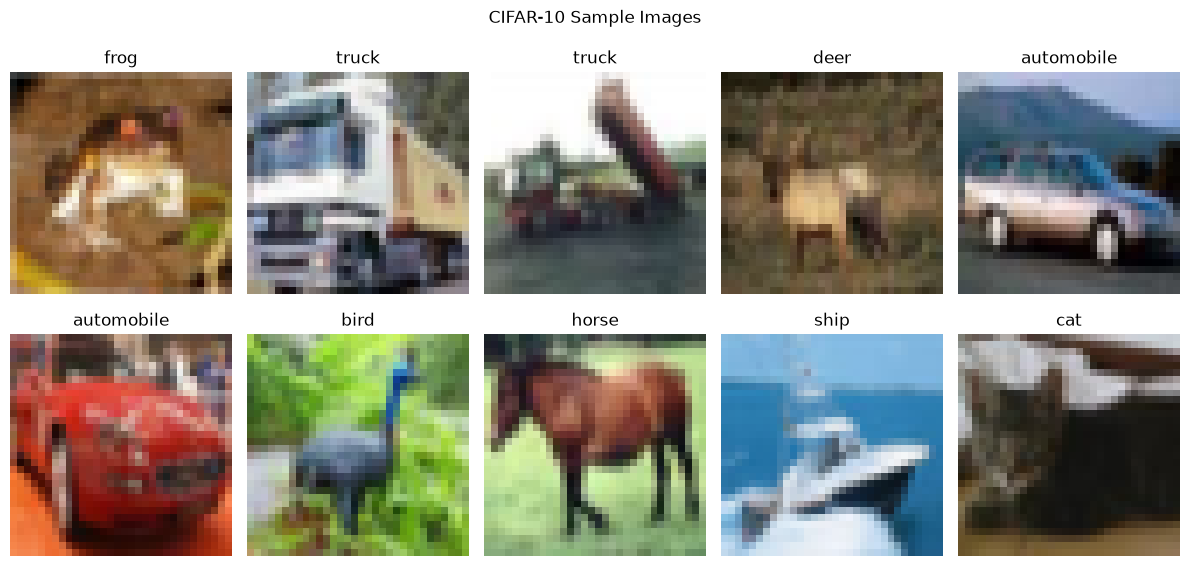

In [2]:
# 获取类别名称
classes = train_dataset.classes

# 显示前 10 张图片
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    # 将 Tensor 转换为 Matplotlib 所需的格式
    image = image.permute(1, 2, 0)

    ax.imshow(image)
    ax.set_title(classes[label])
    ax.axis("off")

plt.suptitle("CIFAR-10 Sample Images")
plt.tight_layout()
plt.show()

In [3]:
# 设置批次大小
batch_size = 128

# 创建训练集加载器
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

# 创建测试集加载器
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

# 查看一批数据
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Pixel range:", images.min().item(), images.max().item())
print("First 10 labels:", labels[:10].tolist())

Images shape: torch.Size([128, 3, 32, 32])
Labels shape: torch.Size([128])
Pixel range: 0.0 1.0
First 10 labels: [1, 8, 9, 8, 6, 9, 0, 2, 0, 4]


In [4]:
from model_resnet import ResNet18, PlainCNN

# 创建普通 CNN 和 ResNet-18
cnn_model = PlainCNN().to(device)
resnet_model = ResNet18().to(device)

# 创建测试输入
test_input = torch.randn(4, 3, 32, 32).to(device)

# 前向传播测试
cnn_model.eval()
resnet_model.eval()

with torch.no_grad():
    cnn_output = cnn_model(test_input)
    resnet_output = resnet_model(test_input)

print("Input shape:", test_input.shape)
print("CNN output:", cnn_output.shape)
print("ResNet output:", resnet_output.shape)

# 统计模型参数量
cnn_params = sum(p.numel() for p in cnn_model.parameters())
resnet_params = sum(p.numel() for p in resnet_model.parameters())

print("CNN parameters:", cnn_params)
print("ResNet parameters:", resnet_params)

Input shape: torch.Size([4, 3, 32, 32])
CNN output: torch.Size([4, 10])
ResNet output: torch.Size([4, 10])
CNN parameters: 391946
ResNet parameters: 11173962


In [1]:
import pandas as pd
from pathlib import Path

results_dir = Path("results")

# 读取四组实验汇总
model_names = ["cnn", "resnet", "no_shortcut", "resnet_aug"]

summaries = []

for name in model_names:
    df = pd.read_csv(results_dir / f"{name}_summary.csv")
    df["experiment"] = name
    summaries.append(df)

comparison = pd.concat(summaries, ignore_index=True)

# 保存 CNN 与 ResNet 对照结果
cnn_vs_resnet = comparison[
    comparison["experiment"].isin(["cnn", "resnet"])
].copy()

cnn_vs_resnet.to_csv(
    results_dir / "cnn_vs_resnet.csv",
    index=False
)

# 保存两个消融实验的结果
ablation = comparison[
    comparison["experiment"].isin([
        "resnet", "no_shortcut", "resnet_aug"
    ])
].copy()

ablation.to_csv(
    results_dir / "ablation_study.csv",
    index=False
)

# 显示完整比较结果
display(
    comparison[
        ["experiment", "best_val_accuracy",
         "test_accuracy", "runtime_seconds"]
    ]
)

,experiment,best_val_accuracy,test_accuracy,runtime_seconds
0,cnn,0.7456,0.7476,63.287765
1,resnet,0.8318,0.8211,233.436635
2,no_shortcut,0.8356,0.8189,212.896133
3,resnet_aug,0.8410,0.8352,256.281071


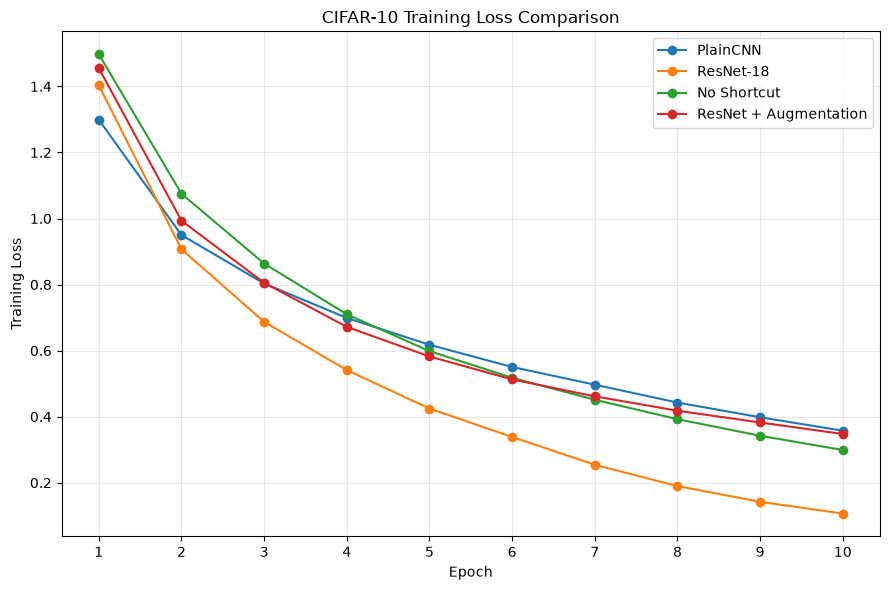

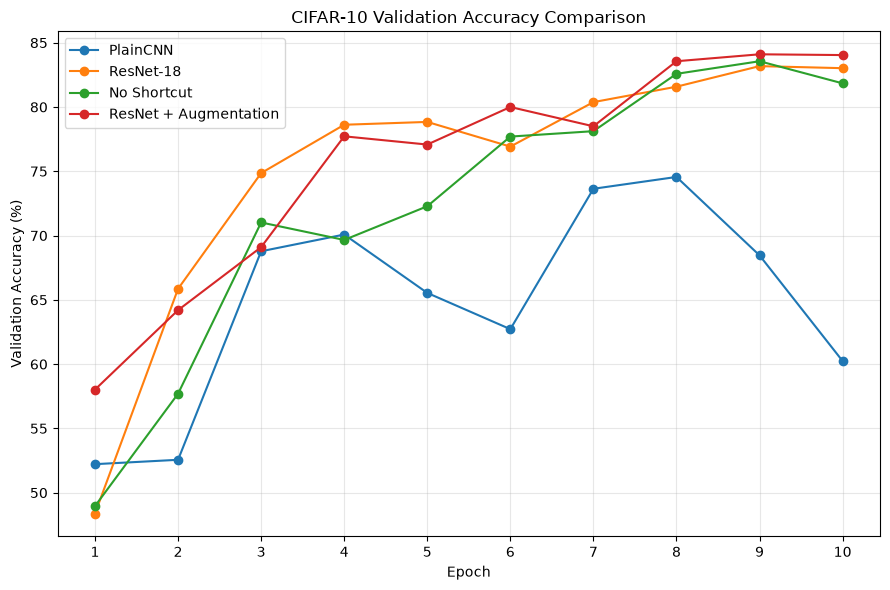

In [2]:
import matplotlib.pyplot as plt

# 读取四组实验的每轮指标
histories = {}

for name in model_names:
    histories[name] = pd.read_csv(
        results_dir / f"{name}_history.csv"
    )

labels = {
    "cnn": "PlainCNN",
    "resnet": "ResNet-18",
    "no_shortcut": "No Shortcut",
    "resnet_aug": "ResNet + Augmentation"
}

# 绘制训练损失曲线
plt.figure(figsize=(9, 6))

for name, df in histories.items():
    plt.plot(
        df["epoch"],
        df["train_loss"],
        marker="o",
        label=labels[name]
    )

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("CIFAR-10 Training Loss Comparison")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    results_dir / "loss_curve.png",
    dpi=300
)
plt.show()

# 绘制验证准确率曲线
plt.figure(figsize=(9, 6))

for name, df in histories.items():
    plt.plot(
        df["epoch"],
        df["val_accuracy"] * 100,
        marker="o",
        label=labels[name]
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("CIFAR-10 Validation Accuracy Comparison")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    results_dir / "accuracy_curve.png",
    dpi=300
)
plt.show()